# Multi-hazard time-enabled layers → ArcGIS (Gannon storyline)

Builds hourly polygons of hazard areas, of places where hazards overlap, and of grid-stress signals, then publishes them as **time-enabled hosted feature layers** in one web map that an Experience Builder app can point at.

The layers follow the storyline order from the task plan:

| Stage | Layer key | What it shows | Geometry | Time |
|---|---|---|---|---|
| 1 Space-weather forcing | `hazard_space_weather` | NOAA geoelectric field, hourly max \|E\| ≥ threshold | 50 km grid cells | hourly |
| 2 Terrestrial conditions | `hazard_convective` | Radar severe-storm signatures (SWDI hail ≥ 1 in or tornado vortex) | 50 km grid cells | hourly |
| 2 Terrestrial conditions | `hazard_terrestrial_weather`, `hazard_wildfire` | Wind / fire grids, only when the team's daily files are present | 50 km grid cells | hourly |
| 1+2 Overlap | `overlap` | Cells where ≥ 2 hazards are active in the same hour, with the hazard combination | 50 km grid cells | hourly |
| 3 Grid stress | `grid_tads_regions` | NERC TADS transmission circuit trips (from `outputs/`), counted per NERC region | NERC region | hourly |
| 3 Grid stress | `grid_eagle_i` | Eagle-I county outages, only when the Eagle-I file is present | county | hourly |
| 3 Grid stress | `grid_thd_sites` | Whisker Labs THD sensor cities (from `outputs/thd_conus_city_map.png`) | point | hourly if THD files present, else static |
| Unknowns | `unknown_coverage` | Places/hours where a hazard **cannot** be assessed (no data, or far from any magnetometer) | 50 km grid cells / AOI | event window or per gap |
| Context | `context_psps_circuits` | PSPS circuit footprints (from `outputs/circuits_only_sanity_map.html`) | circuit polygon | static |

Stage 4 (outcome: anomaly / near miss / non-event) is left for analysts as the `outcome_label` column in the storyline table.

**Gaps are never silent.** Every layer, and every grid signal that is not yet available, gets a row in the data registry. The registry is saved to `outputs/` and written into the web map description.

### How to run
0. **Kernel: use the `gdal_test` conda env.** It has `arcgis` plus GDAL and is likely where `Untitled.ipynb` published. The `multihazard` env has no GDAL bindings, so `arcgis` would upload through shapefiles. With pyshp 3 that path crashes, and shapefiles would also drop the time of day and cut field names to 10 characters. Building the layers works in either env; only publishing needs GDAL.
1. Set `EVENT_KEY` in the next cell. `gannon_2024` is the default. `marapr_2023` uses the 2023 files already in `~/Downloads/mh_notebook_data`.
2. Run all cells with `PUBLISH_TO_ARCGIS = False`. Everything is built locally: a GeoPackage, the registry CSV, the storyline CSV/PNG, and a preview map in `notebooks/outputs/`.
3. Check the preview. Then set `PUBLISH_TO_ARCGIS = True` and rerun from the publish section.

Public inputs (NOAA geoelectric files, NOAA SWDI radar signatures) download into `~/Downloads/mh_notebook_data/` on first run, about 0.5 GB for Gannon.

## 1. Run settings

In [ ]:
EVENT_KEY = "gannon_2024"        # "gannon_2024" or "marapr_2023"

PUBLISH_TO_ARCGIS = True        # True → publish hosted layers + web map
GIS_PROFILE = "geosaurus"        # saved ArcGIS profile (same one Untitled.ipynb uses)
ARCGIS_FOLDER = "multihazard"    # content folder for the layers and web map (created if missing)
WEB_MAP_ITEM_ID = ""             # optional: overwrite this existing web map so Experience Builder links stay the same
DELETE_PREVIOUS_LAYERS = False   # True → permanently delete this event's layers from earlier runs (after the new ones publish)

ALLOW_DOWNLOADS = True           # fetch public NOAA inputs into the local cache when missing

In [2]:
import os
os.environ.setdefault("ARCGIS_IO_ENGINE", "gdal")  # upload via file geodatabase so hourly timestamps survive
os.environ["PROJ_NETWORK"] = "OFF"  # no on-demand datum grids: a failed grid download returns inf coordinates
                                    # and breaks to_crs; metre-level shifts don't matter on a 50 km grid

import ast
import io
import json
import re
import warnings
from pathlib import Path
from uuid import uuid4

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import shapely
import requests
import matplotlib.pyplot as plt
from affine import Affine
import pyproj
from pyproj import Transformer
from rasterio.features import shapes
from scipy import ndimage
from scipy.spatial import cKDTree
from shapely.geometry import shape

pyproj.network.set_network_enabled(False)  # also covers kernels where pyproj was already imported

warnings.filterwarnings("ignore", message="All-NaN slice encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="invalid value encountered", category=RuntimeWarning)  # shapely on the legacy NERC map


def _find_project_dir(start: Path) -> Path:
    for p in [start, *start.parents]:
        for cand in (p, p / "Projects" / "NASA-disasters-grid-resilience"):
            if (cand / "data" / "analysis_grid_CONUS_50km.nc").exists() and (cand / "notebooks").exists():
                return cand
    raise FileNotFoundError("Run this notebook from inside the NASA-disasters-grid-resilience project.")


PROJECT_DIR = _find_project_dir(Path.cwd().resolve())
DATA_DIR = PROJECT_DIR / "data"
OUTPUTS_DIR = PROJECT_DIR / "notebooks" / "outputs"
DATA_CACHE = Path.home() / "Downloads" / "mh_notebook_data"   # large inputs stay outside the repo
ANALYSIS_CRS = "EPSG:5070"                                      # CONUS Albers, same as the 50 km grid

print("Project:", PROJECT_DIR)
print("Data cache:", DATA_CACHE)

Project: /Users/nza/GitHub/mh_project/Projects/NASA-disasters-grid-resilience
Data cache: /Users/nza/Downloads/mh_notebook_data


## 2. Event presets and hazard thresholds

Each event names its sources per hazard family. A source whose files are missing is registered as missing, not skipped silently. All timestamps are UTC (stored as timezone-naive values, which ArcGIS reads as UTC).

In [3]:
EVENTS = {
    "gannon_2024": {
        "event_id": "gannon_2024",
        "title": "Gannon geomagnetic storm, May 2024",
        "start": "2024-05-08 00:00:00",
        "end": "2024-05-15 23:59:59",
        "focus": ("2024-05-10 00:00:00", "2024-05-12 23:59:59"),   # storyline window (web map time slider opens here)
        "aoi": DATA_DIR / "selected_states_May2024_event.geojson",
        "space_weather": {
            "kind": "noaa_geoe",
            "dir": DATA_CACHE / "noaa_geoe_2024event",
            # three-city extracts in outputs/: fallback when the NOAA grid is unavailable, and a cross-check
            "fallback_csvs": sorted(OUTPUTS_DIR.glob("geoE_ExEy_timeseries_*.csv")),
        },
        "convective": {"kind": "swdi_web", "cache_dir": DATA_CACHE / "swdi_2024event"},
        "terrestrial_weather": {"kind": "daily_grid", "dir": DATA_CACHE / "weather_CONUS_2024event", "prefix": "weather_CONUS"},
        "wildfire": {"kind": "daily_grid", "dir": DATA_CACHE / "fires_analysis_grid_2024event", "prefix": "fires_analysis_grid"},
        "tads_csv": OUTPUTS_DIR / "tads_ac_multi_trip_per_file.csv",
        "tads_source_files": ["2024"],
        "eagle_i_csv": DATA_CACHE / "eaglei_outages_2024.csv",
        "thd_dir": DATA_CACHE / "whisker_thd_2024event",          # thd_data_for_*_10_sensors.csv
        "psps_circuits_html": OUTPUTS_DIR / "circuits_only_sanity_map.html",
    },
    "marapr_2023": {
        "event_id": "marapr_2023",
        "title": "March–April 2023 multi-hazard event",
        "start": "2023-03-26 00:00:00",
        "end": "2023-04-08 23:59:59",
        "focus": None,
        "aoi": DATA_DIR / "selected_states_MarchApril2023_event.geojson",
        "space_weather": {"kind": "site_nc", "path": DATA_CACHE / "mcgranaghan-rawdata.nc", "var": "Eh"},
        "convective": {"kind": "grid_file", "path": Path.home() / "Downloads" / "swdi_nx3_hourly_50km_conus.nc"},
        "terrestrial_weather": {"kind": "daily_grid", "dir": DATA_CACHE / "weather_CONUS_2023event", "prefix": "weather_CONUS"},
        "wildfire": {"kind": "daily_grid", "dir": DATA_CACHE / "fires_analysis_grid_2023event", "prefix": "fires_analysis_grid"},
        "tads_csv": OUTPUTS_DIR / "tads_ac_multi_trip_per_file.csv",
        "tads_source_files": ["2023"],
        "eagle_i_csv": DATA_CACHE / "eaglei_outages_2023.csv",
        "thd_dir": None,
        "psps_circuits_html": OUTPUTS_DIR / "circuits_only_sanity_map.html",
    },
}

EVENT = EVENTS[EVENT_KEY]
EVENT_ID = EVENT["event_id"]
EVENT_START = pd.Timestamp(EVENT["start"])
EVENT_END = pd.Timestamp(EVENT["end"])
STEP = pd.Timedelta("1h")
HOURS = pd.date_range(EVENT_START.floor("h"), EVENT_END.floor("h"), freq="h")
FOCUS_START, FOCUS_END = (pd.Timestamp(t) for t in (EVENT.get("focus") or (EVENT_START, EVENT_END)))

print(f"{EVENT['title']}: {EVENT_START} → {EVENT_END} UTC ({len(HOURS)} hourly steps)")

Gannon geomagnetic storm, May 2024: 2024-05-08 00:00:00 → 2024-05-15 23:59:59 UTC (192 hourly steps)


In [4]:
# Threshold rules use the same format as Untitled.ipynb / create_hazard_polygons.ipynb:
# {"thresholds": {var: {"operator": ">=", "value": x}}, "combine": "and" | "or"}  or  {"expression": callable(ds)}
HAZARD_RULES = {
    "space_weather": {
        "label": "Geoelectric field |E| (hourly max)",
        "stage": "1_space_weather_forcing",
        "value_var": "E_hmax",
        "units": "mV/km",
        "config": {"thresholds": {"E_hmax": {"operator": ">=", "value": 1000.0}}},
        "min_pixels": 2,
    },
    "convective": {
        "label": "Severe convection (radar hail >= 1 in or tornado vortex signature)",
        "stage": "2_terrestrial_conditions",
        "value_var": "nx3hail_MAXSIZE_max",
        "units": "in (max hail size)",
        "config": {
            "thresholds": {
                "nx3hail_MAXSIZE_max": {"operator": ">=", "value": 1.0},
                "nx3tvs_counts": {"operator": ">=", "value": 1},
            },
            "combine": "or",
        },
        "min_pixels": 1,
    },
    "terrestrial_weather": {
        "label": "High wind (10 m wind speed)",
        "stage": "2_terrestrial_conditions",
        "value_var": "wspd10",
        "units": "m/s",
        "config": {"thresholds": {"wspd10": {"operator": ">=", "value": 15.0}}},
        "min_pixels": 1,
    },
    "wildfire": {
        "label": "Active fire (fire radiative power)",
        "stage": "2_terrestrial_conditions",
        "value_var": "frp",
        "units": "MW",
        "config": {"thresholds": {"frp": {"operator": ">=", "value": 100.0}}},
        "min_pixels": 2,
    },
}

# Per-event changes. The 2023 site product (mcgranaghan-rawdata.nc) has no units and a much smaller
# scale than the NOAA product (hourly-max 99th percentile ≈ 85), so it gets its own threshold.
RULE_OVERRIDES = {
    "marapr_2023": {
        "space_weather": {
            "label": "Eh (hourly max, McGranaghan site product)",
            "units": "Eh (source units)",
            "config": {"thresholds": {"E_hmax": {"operator": ">=", "value": 150.0}}},  # ~top 0.3% of site-hours
        },
    },
}
for _family, _update in RULE_OVERRIDES.get(EVENT_KEY, {}).items():
    HAZARD_RULES[_family] = {**HAZARD_RULES[_family], **_update}

MIN_OVERLAP_HAZARDS = 2       # a cell counts as "overlapping" when at least this many hazards are active
TRACK_MIN_IOU = 0.20          # region keeps its track_id between hours when overlap (IoU) >= this
CLIP_TO_AOI = True            # only keep grid cells whose centre is inside the event states
GEOE_GRID_MATCH_KM = 75       # max distance from a grid cell to the NOAA/site point it takes values from
GEOE_LOW_CONFIDENCE_KM = 1000 # flag cells whose geoelectric value comes from > this far from a magnetometer
GEOE_CSV_RADIUS_KM = 150      # fallback only: how far each of the three city series is trusted
TADS_TIME_ZONE = "UTC"        # assumption: TADS outage start times treated as UTC (verify)
TADS_BIN = "1h"               # time bin for TADS trips per region
EAGLE_MIN_CUSTOMERS_OUT = 500 # county-hours below this are not drawn
SIMPLIFY_M = 2000             # simplification tolerance (m) for big boundary polygons


def threshold_text(config):
    if config.get("expression") is not None:
        return "custom expression"
    parts = []
    for var, rule in config["thresholds"].items():
        rule = rule if isinstance(rule, dict) else {"operator": ">=", "value": rule}
        op = rule.get("operator", ">=")
        rhs = f"[{rule['min']}, {rule['max']}]" if op in ("between", "outside") else rule["value"]
        parts.append(f"{var} {op} {rhs}")
    return f" {config.get('combine', 'and').upper()} ".join(parts)


for fam, rule in HAZARD_RULES.items():
    print(f"{fam:20s} {threshold_text(rule['config'])}")

space_weather        E_hmax >= 1000.0
convective           nx3hail_MAXSIZE_max >= 1.0 OR nx3tvs_counts >= 1
terrestrial_weather  wspd10 >= 15.0
wildfire             frp >= 100.0


## 3. Layer schema and data registry

Every published layer carries the same core fields, so new context layers (PJM, raw TADS, social vulnerability, …) can be added later without redesigning the web map or app.

| Field | Meaning |
|---|---|
| `event_id`, `layer_key`, `family`, `storyline_stage` | What the feature is and where it sits in the storyline |
| `signal`, `value`, `value_units`, `threshold` | The measured quantity, its value for this feature (max in the polygon), and the rule that triggered it |
| `start_time`, `end_time` | UTC time window. The layer's time settings use these two fields |
| `n_hazards`, `hazard_combo` | For overlap polygons: how many and which hazards coincide |
| `track_id`, `pixel_count`, `area_km2` | Region tracking across hours (stable while the region persists) and size |
| `data_status` | `observed`, `modeled`, `derived`, `unknown`, `not_available_locally` |
| `geo_precision` | `grid_50km`, `site_radius`, `nerc_region`, `county`, `point`, `circuit_polygon`, `aoi` |
| `source`, `notes` | Provenance and caveats |

In [5]:
SCHEMA = {
    "event_id": "str", "layer_key": "str", "family": "str", "storyline_stage": "str",
    "signal": "str", "start_time": "datetime", "end_time": "datetime",
    "value": "float", "value_units": "str", "threshold": "str",
    "n_hazards": "int", "hazard_combo": "str",
    "track_id": "int", "pixel_count": "int", "area_km2": "float",
    "data_status": "str", "geo_precision": "str", "source": "str", "notes": "str",
}
_EMPTY = {"str": "", "float": np.nan, "int": -1, "datetime": pd.NaT}


def conform(gdf, **fields):
    """Give a GeoDataFrame the shared schema. `fields` fill columns the frame doesn't already have."""
    out = gpd.GeoDataFrame(gdf.copy(), geometry="geometry", crs=gdf.crs or ANALYSIS_CRS).to_crs(ANALYSIS_CRS)
    out["event_id"] = EVENT_ID
    for col, kind in SCHEMA.items():
        if col not in out.columns:
            out[col] = fields.get(col, _EMPTY[kind])
        if kind == "datetime":
            ts = pd.to_datetime(out[col], utc=True)
            out[col] = ts.dt.tz_convert("UTC").dt.tz_localize(None).astype("datetime64[ms]")
        elif kind == "float":
            out[col] = pd.to_numeric(out[col], errors="coerce").astype("float64")
        elif kind == "int":
            out[col] = pd.to_numeric(out[col], errors="coerce").fillna(-1).astype("int32")
        else:
            out[col] = out[col].fillna("").astype(str)
    extras = [c for c in out.columns if c not in SCHEMA and c != "geometry"]
    return out[list(SCHEMA) + extras + ["geometry"]]


def empty_layer():
    return conform(gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=ANALYSIS_CRS))


REGISTRY = {}


def register(key, family, stage, status, *, n_features=None, geo_precision="", source="", notes=""):
    REGISTRY[key] = {
        "layer_key": key, "family": family, "storyline_stage": stage, "status": status,
        "n_features": n_features, "geo_precision": geo_precision, "source": source, "notes": notes,
    }


# Grid-side and context signals named in the task plan that this notebook cannot ingest yet.
NOT_YET_AVAILABLE = [
    ("grid_component_outages", "grid_stress", "Component-level outages with locations",
     "TADS rows are anonymized (AliasID); needs the raw TADS extract or utility OMS data with substation/line IDs."),
    ("grid_voltage_frequency", "grid_stress", "Voltage / frequency (Whisker Labs Frequency, sags, swells)",
     "JSON files exist on a collaborator machine (Whisker_Labs_Data_March2026); copy them into the data cache to add."),
    ("grid_gic_measurements", "grid_stress", "Measured GIC (NERC GIC Gannon dataset)",
     "Exists on a collaborator machine (NERC_GIC_Gannon_Waghule); not yet ingested."),
    ("grid_utility_warnings", "grid_stress", "Utility warning / conservative-operations announcements", "No source identified yet."),
    ("grid_pjm_operations", "grid_stress", "PJM operations data", "PJM notebooks are exploratory; no event extract yet."),
    ("context_social_vulnerability", "context", "Social vulnerability (e.g. CDC SVI)", "Not yet ingested."),
    ("context_kp_dst", "space_weather", "Kp / Dst indices", "Global indices; storyline uses the CONUS max |E| from the NOAA product instead."),
]
for key, family, signal, why in NOT_YET_AVAILABLE:
    register(key, family, "3_grid_stress" if family == "grid_stress" else "4_context", "not_yet_available", source=signal, notes=why)

## 4. Analysis grid and shared helpers

Everything lands on the project's 50 km CONUS Albers grid (`data/analysis_grid_CONUS_50km.nc`), the same grid the team's weather and wildfire files use. That makes hazards directly comparable cell by cell, so overlap is a simple per-cell count.

In [6]:
GRID = xr.open_dataset(DATA_DIR / "analysis_grid_CONUS_50km.nc")
GX, GY = GRID["x"].values, GRID["y"].values
DX, DY = float(GX[1] - GX[0]), float(GY[1] - GY[0])
CELL_KM2 = abs(DX * DY) / 1e6
XX, YY = np.meshgrid(GX, GY)
TO_ALBERS = Transformer.from_crs("EPSG:4326", ANALYSIS_CRS, always_xy=True)
GRID_TRANSFORM = Affine(DX, 0.0, GX[0] - DX / 2, 0.0, DY, GY[0] - DY / 2)  # x/y are cell centres

AOI = gpd.read_file(EVENT["aoi"]).to_crs(ANALYSIS_CRS)
AOI_UNION = AOI.union_all()
AOI_SIMPLE = shapely.simplify(AOI_UNION, SIMPLIFY_M)
IN_AOI = shapely.contains_xy(AOI_UNION, XX, YY) if CLIP_TO_AOI else np.ones(XX.shape, bool)
IN_AOI_DA = xr.DataArray(IN_AOI, dims=("y", "x"), coords={"y": GY, "x": GX})

print(f"Grid {len(GY)}×{len(GX)} cells of {CELL_KM2:,.0f} km²; {IN_AOI.sum():,} cells inside the {len(AOI)} event states")


def to_dataset(arrays, attrs=None):
    """{name: (time, y, x) array} → Dataset on HOURS × analysis grid."""
    return xr.Dataset(
        {k: (("time", "y", "x"), v) for k, v in arrays.items()},
        coords={"time": HOURS, "y": GY, "x": GX},
        attrs=attrs or {},
    )


def lonlat_to_cell(lon, lat):
    """Grid-cell indices for lon/lat points (ok=False when outside the grid)."""
    x, y = TO_ALBERS.transform(np.asarray(lon, float), np.asarray(lat, float))
    ix = np.rint((x - GX[0]) / DX).astype(int)
    iy = np.rint((y - GY[0]) / DY).astype(int)
    ok = (ix >= 0) & (ix < len(GX)) & (iy >= 0) & (iy < len(GY))
    return np.clip(ix, 0, len(GX) - 1), np.clip(iy, 0, len(GY) - 1), ok


def nearest_point_index(lon, lat, max_km):
    """For each grid cell, the index of the nearest source point, or -1 when none is within max_km."""
    px, py = TO_ALBERS.transform(np.asarray(lon, float), np.asarray(lat, float))
    dist, idx = cKDTree(np.column_stack([px, py])).query(np.column_stack([XX.ravel(), YY.ravel()]), k=1)
    return np.where(dist <= max_km * 1000, idx, -1).reshape(XX.shape)


def spread_points(values_tp, idx_grid):
    """(time, point) values → (time, y, x) grid using a nearest-point index; NaN where idx == -1."""
    out = np.full((values_tp.shape[0], *idx_grid.shape), np.nan, dtype="float32")
    ok = idx_grid >= 0
    out[:, ok] = values_tp[:, idx_grid[ok]]
    return out


def regrid_to_analysis(ds, keep_vars=None):
    """Put an hourly gridded Dataset (x/y in EPSG:5070) on the analysis grid and the event's HOURS axis."""
    if keep_vars:
        ds = ds[[v for v in keep_vars if v in ds.data_vars]]
    ds = ds.assign_coords(time=pd.to_datetime(ds["time"].values).floor("h"))
    ds = ds.isel(time=~ds.get_index("time").duplicated())
    same = ds.sizes["x"] == len(GX) and ds.sizes["y"] == len(GY) and np.allclose(ds["x"], GX) and np.allclose(ds["y"], GY)
    ds = ds.assign_coords(x=GX, y=GY) if same else ds.interp(x=GX, y=GY, method="nearest")
    ds = ds.where(ds > -900)  # fill values used in the team's files
    return ds.reindex(time=HOURS).transpose("time", "y", "x")


def download(url, dest, timeout=180):
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(dest.suffix + ".part")
    try:
        with requests.get(url, stream=True, timeout=timeout) as r:
            if r.status_code == 404:
                return False
            r.raise_for_status()
            with open(tmp, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
        tmp.replace(dest)
        return True
    except requests.RequestException as exc:
        print(f"  download failed: {url} ({exc})")
        tmp.unlink(missing_ok=True)
        return False

Grid 55×104 cells of 2,500 km²; 2,080 cells inside the 35 event states


## 5. Hazard loaders

Every loader returns the same thing: an hourly Dataset on the analysis grid, plus provenance and any coverage-gap masks.

- **Space weather.** The NOAA SWPC empirical geoelectric product (1-minute Ex/Ey at about 3,400 points) is downloaded per day. The loader takes the hourly max of |E| = √(Ex² + Ey²). Each point also carries its distance to the nearest magnetometer, and cells farther than `GEOE_LOW_CONFIDENCE_KM` are flagged as low confidence. If the NOAA files can't be fetched, the three city series in `outputs/` are used instead, and everything outside their radius is flagged unknown.
- **Convective.** NOAA SWDI radar signatures (hail, tornado vortex, mesocyclone) are pulled in 15°×15° tiles (the service limit), then counted and maxed per grid cell per hour. Variable names match the team's `swdi_nx3_hourly_50km_conus.nc`.
- **Wind / wildfire.** The team's daily `weather_CONUS_YYYYMMDD.nc` / `fires_analysis_grid_YYYYMMDD.nc` files, using the same reader as `Untitled.ipynb`.

In [7]:
NOAA_GEOE_URL = "https://services.swpc.noaa.gov/netcdf/geoelectric/InterMagEarthScope/{d:%Y%m%d}-empirical-EMTF-2022.12-2022.12.nc"
GEOE_CSV_CITY_COORDS = {  # lat, lon of the three city extracts in outputs/
    "Minneapolis": (44.98, -93.27),
    "Seattle": (47.61, -122.33),
    "Washington_DC": (38.91, -77.04),
}


def _event_days():
    return pd.date_range(EVENT_START.normalize(), EVENT_END.normalize(), freq="D")


def load_space_weather_noaa(cfg):
    out_dir = Path(cfg["dir"])
    files, missing = [], []
    for d in _event_days():
        fp = out_dir / f"{d:%Y%m%d}-empirical-EMTF-2022.12-2022.12.nc"
        if not fp.exists() and ALLOW_DOWNLOADS:
            print(f"  downloading NOAA geoE {d:%Y-%m-%d} …")
            download(NOAA_GEOE_URL.format(d=d), fp)
        (files if fp.exists() else missing).append(fp)

    if not files:
        if cfg.get("fallback_csvs"):
            print("  NOAA geoE unavailable → falling back to the city CSVs in outputs/")
            return load_space_weather_csv({"paths": cfg["fallback_csvs"]})
        raise FileNotFoundError(f"No NOAA geoE files in {out_dir}")

    hourly_parts, lat, lon, obs_dist, n_bad_minutes = [], None, None, None, 0
    for fp in files:
        with xr.open_dataset(fp, decode_times=False) as ds:
            ref = pd.Timestamp(str(ds["time"].attrs.get("REFTIME", fp.name[:8])))
            secs = ds["time"].values
            ok = np.isfinite(secs) & (secs >= 0) & (secs < 2 * 86400)   # some minutes carry the netCDF fill value (9.97e36)
            t = ref + pd.to_timedelta(secs[ok], unit="s")
            ex = ds["Ex"].values[ok].astype("float32")
            ey = ds["Ey"].values[ok].astype("float32")
            ex[(ex <= -900) | (np.abs(ex) > 1e6)] = np.nan
            ey[(ey <= -900) | (np.abs(ey) > 1e6)] = np.nan
            e = np.hypot(ex, ey)
            n_bad_minutes += int((~ok).sum())
            hourly_parts.append(pd.DataFrame(e, index=pd.DatetimeIndex(t).floor("h")).groupby(level=0).max())
            if lat is None:
                lat = ds["latitude"].values.astype(float)
                lon = ds["longitude"].values.astype(float)
                lon = np.where(lon > 180, lon - 360, lon)
                obs_dist = ds["distance"].values.astype(float)
            else:
                obs_dist = np.fmax(obs_dist, ds["distance"].values.astype(float))  # keep the most pessimistic day

    hourly = pd.concat(hourly_parts).groupby(level=0).max().reindex(HOURS)   # (hour, point)
    idx = nearest_point_index(lon, lat, GEOE_GRID_MATCH_KM)
    ds_out = to_dataset({"E_hmax": spread_points(hourly.to_numpy(np.float32), idx)})
    cell_obs_dist = np.where(idx >= 0, obs_dist[np.clip(idx, 0, None)], np.nan)
    ds_out["obs_distance_km"] = (("y", "x"), cell_obs_dist.astype("float32"))

    return {
        "ds": ds_out,
        "coverage_var": "E_hmax",
        "gap_masks": {
            f"geoelectric value from > {GEOE_LOW_CONFIDENCE_KM} km from nearest magnetometer (low confidence)":
                np.isfinite(cell_obs_dist) & (cell_obs_dist > GEOE_LOW_CONFIDENCE_KM),
        },
        "series": hourly.max(axis=1).rename("geoe_conus_max_mV_km"),
        "points": {"lat": lat, "lon": lon, "hourly": hourly},
        "data_status": "modeled",
        "geo_precision": "grid_50km",
        "source": "NOAA SWPC empirical EMTF geoelectric field (InterMagEarthScope)",
        "notes": (f"{len(files)}/{len(files) + len(missing)} daily files; |E| = hypot(Ex, Ey), hourly max of 1-min values; "
                  f"{n_bad_minutes} minutes missing in source files"),
    }


def load_space_weather_noaa_or_csv(cfg):
    """NOAA grid first; if that fails for any reason, the city CSVs in outputs/ (and say why)."""
    try:
        return load_space_weather_noaa(cfg)
    except Exception as exc:
        if not cfg.get("fallback_csvs"):
            raise
        print(f"  NOAA geoE failed ({type(exc).__name__}: {exc}) → using the city CSVs in outputs/")
        result = load_space_weather_csv({"paths": cfg["fallback_csvs"]})
        result["notes"] += f"; NOAA grid failed: {type(exc).__name__}: {exc}"
        return result


def load_space_weather_csv(cfg):
    series = {}
    for p in cfg["paths"]:
        city = Path(p).stem.replace("geoE_ExEy_timeseries_", "")
        if city not in GEOE_CSV_CITY_COORDS:
            print(f"  no coordinates for {city}; skipped")
            continue
        d = pd.read_csv(p, parse_dates=["time"])
        series[city] = np.hypot(d["Ex"], d["Ey"]).groupby(d["time"].dt.floor("h")).max()
    if not series:
        raise FileNotFoundError("No usable geoE city CSVs")
    hourly = pd.DataFrame(series).reindex(HOURS)
    lat, lon = zip(*(GEOE_CSV_CITY_COORDS[c] for c in hourly.columns))
    idx = nearest_point_index(lon, lat, GEOE_CSV_RADIUS_KM)
    return {
        "ds": to_dataset({"E_hmax": spread_points(hourly.to_numpy(np.float32), idx)}),
        "coverage_var": "E_hmax",
        "gap_masks": {},
        "series": hourly.max(axis=1).rename("geoe_conus_max_mV_km"),
        "points": {"lat": np.array(lat), "lon": np.array(lon), "hourly": hourly},
        "data_status": "modeled",
        "geo_precision": "site_radius",
        "source": "outputs/geoE_ExEy_timeseries_*.csv (NOAA geoE at 3 cities)",
        "notes": f"Fallback: each city series applied within {GEOE_CSV_RADIUS_KM} km; everything else is unknown",
    }


def load_space_weather_sites_nc(cfg):
    ds = xr.open_dataset(cfg["path"])
    var = cfg.get("var", "Eh")
    da = ds[var].sel(time=slice(EVENT_START, EVENT_END)).resample(time="1h").max()
    hourly = pd.DataFrame(da.transpose("time", "site").values, index=pd.DatetimeIndex(da["time"].values)).reindex(HOURS)
    idx = nearest_point_index(ds["longitude"].values, ds["latitude"].values, GEOE_GRID_MATCH_KM)
    return {
        "ds": to_dataset({"E_hmax": spread_points(hourly.to_numpy(np.float32), idx)}),
        "coverage_var": "E_hmax",
        "gap_masks": {},
        "series": hourly.max(axis=1).rename("geoe_conus_max_mV_km"),
        "data_status": "modeled",
        "geo_precision": "grid_50km",
        "source": Path(cfg["path"]).name,
        "notes": f"{var} hourly max per site, nearest site within {GEOE_GRID_MATCH_KM} km",
    }

In [8]:
SWDI_URL = "https://www.ncei.noaa.gov/swdiws/csv/{dataset}/{start}:{end}?bbox={bbox}"
SWDI_TILES = [(w, s, min(w + 15, -66), min(s + 13, 50)) for w in (-125, -110, -95, -80) for s in (24, 37)]
SWDI_FIELDS = {"nx3hail": ["PROB", "SEVPROB", "MAXSIZE"], "nx3tvs": ["MAX_SHEAR", "MXDV"], "nx3meso": []}


def fetch_swdi(dataset, cache_dir):
    """All SWDI records of one dataset for the event window (cached as CSV). End date in the URL is exclusive."""
    cache = Path(cache_dir) / f"{dataset}_{EVENT_START:%Y%m%d}_{EVENT_END:%Y%m%d}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    if not ALLOW_DOWNLOADS:
        raise FileNotFoundError(cache)
    start, end = f"{EVENT_START:%Y%m%d}", f"{EVENT_END.normalize() + pd.Timedelta(days=1):%Y%m%d}"
    parts = []
    for w, s, e, n in SWDI_TILES:
        url = SWDI_URL.format(dataset=dataset, start=start, end=end, bbox=f"{w},{s},{e},{n}")
        r = requests.get(url, timeout=300)
        r.raise_for_status()
        if r.text.lower().startswith("error"):
            raise RuntimeError(f"SWDI error: {r.text[:200]}")
        body = r.text.split("\nsummary")[0].strip()
        if body and not body.startswith("summary"):
            parts.append(pd.read_csv(io.StringIO(body)))
    df = pd.concat(parts, ignore_index=True).drop_duplicates() if parts else pd.DataFrame(columns=["ZTIME", "LAT", "LON"])
    cache.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(cache, index=False)
    return df


def load_convective_swdi(cfg):
    arrays, counts_note = {}, []
    for dataset, fields in SWDI_FIELDS.items():
        print(f"  SWDI {dataset} …")
        df = fetch_swdi(dataset, cfg["cache_dir"])
        counts = np.zeros((len(HOURS), len(GY), len(GX)), "float32")
        maxes = {f: np.full(counts.shape, np.nan, "float32") for f in fields}
        if len(df):
            t = pd.to_datetime(df["ZTIME"], utc=True).dt.tz_convert(None).dt.floor("h")
            ti = HOURS.get_indexer(t)
            ix, iy, ok = lonlat_to_cell(df["LON"], df["LAT"])
            ok &= ti >= 0
            np.add.at(counts, (ti[ok], iy[ok], ix[ok]), 1)
            for f in fields:
                v = pd.to_numeric(df[f], errors="coerce").to_numpy("float32")
                np.fmax.at(maxes[f], (ti[ok], iy[ok], ix[ok]), v[ok])
        arrays[f"{dataset}_counts"] = counts
        arrays.update({f"{dataset}_{f}_max": a for f, a in maxes.items()})
        counts_note.append(f"{dataset}: {len(df):,} records")
    return {
        "ds": to_dataset(arrays),
        "coverage_var": None,   # absence of a radar signature means "none detected", not "unknown"
        "gap_masks": {},
        "data_status": "observed",
        "geo_precision": "grid_50km",
        "source": "NOAA NCEI Severe Weather Data Inventory (NEXRAD level-3 hail / TVS / meso)",
        "notes": "; ".join(counts_note),
    }


def load_grid_file(cfg):
    ds = xr.open_dataset(cfg["path"])
    rule_vars = list(HAZARD_RULES["convective"]["config"]["thresholds"]) + [HAZARD_RULES["convective"]["value_var"]]
    return {
        "ds": regrid_to_analysis(ds, keep_vars=rule_vars),
        "coverage_var": None,
        "gap_masks": {},
        "data_status": "observed",
        "geo_precision": "grid_50km",
        "source": Path(cfg["path"]).name,
        "notes": "pre-gridded SWDI file, regridded (nearest) to the analysis grid",
    }


def load_daily_grid(cfg, family):
    base = Path(cfg["dir"])
    base = base / "daily" if (base / "daily").exists() else base
    files = [base / f"{cfg['prefix']}_{d:%Y%m%d}.nc" for d in _event_days()]
    found = [f for f in files if f.exists()]
    if not found:
        raise FileNotFoundError(f"no {cfg['prefix']}_YYYYMMDD.nc files in {base}")
    rule = HAZARD_RULES[family]
    keep = list(rule["config"].get("thresholds", {})) + [rule["value_var"]]
    daily = []
    for f in found:
        d = xr.open_dataset(f)
        daily.append(d[[v for v in keep if v in d.data_vars]])
    ds = xr.concat(daily, dim="time", data_vars="minimal", coords="minimal", compat="override")
    return {
        "ds": regrid_to_analysis(ds, keep_vars=keep),
        "coverage_var": rule["value_var"],
        "gap_masks": {},
        "data_status": "observed",
        "geo_precision": "grid_50km",
        "source": f"{cfg['prefix']} daily grids",
        "notes": f"{len(found)}/{len(files)} daily files",
    }


LOADERS = {
    "noaa_geoe": lambda cfg, fam: load_space_weather_noaa_or_csv(cfg),
    "site_nc": lambda cfg, fam: load_space_weather_sites_nc(cfg),
    "swdi_web": lambda cfg, fam: load_convective_swdi(cfg),
    "grid_file": lambda cfg, fam: load_grid_file(cfg),
    "daily_grid": load_daily_grid,
}

In [9]:
HAZARD_DATA = {}
for family, rule in HAZARD_RULES.items():
    cfg = EVENT.get(family)
    key = f"hazard_{family}"
    if cfg is None:
        register(key, family, rule["stage"], "missing_input", notes="no source configured for this event")
        continue
    print(f"Loading {family} ({cfg['kind']}) …")
    try:
        HAZARD_DATA[family] = LOADERS[cfg["kind"]](cfg, family)
    except Exception as exc:
        print(f"  → not available: {type(exc).__name__}: {exc}")
        register(key, family, rule["stage"], "missing_input", source=cfg["kind"], notes=f"{type(exc).__name__}: {exc}")
        continue
    info = HAZARD_DATA[family]
    print(f"  → {info['source']} | {info['notes']}")

print("\nHazard families loaded:", list(HAZARD_DATA))

Loading space_weather (noaa_geoe) …
  → NOAA SWPC empirical EMTF geoelectric field (InterMagEarthScope) | 8/8 daily files; |E| = hypot(Ex, Ey), hourly max of 1-min values; 7 minutes missing in source files
Loading convective (swdi_web) …
  SWDI nx3hail …
  SWDI nx3tvs …
  SWDI nx3meso …
  → NOAA NCEI Severe Weather Data Inventory (NEXRAD level-3 hail / TVS / meso) | nx3hail: 47,711 records; nx3tvs: 4,094 records; nx3meso: 0 records
Loading terrestrial_weather (daily_grid) …
  → not available: FileNotFoundError: no weather_CONUS_YYYYMMDD.nc files in /Users/nza/Downloads/mh_notebook_data/weather_CONUS_2024event
Loading wildfire (daily_grid) …
  → not available: FileNotFoundError: no fires_analysis_grid_YYYYMMDD.nc files in /Users/nza/Downloads/mh_notebook_data/fires_analysis_grid_2024event

Hazard families loaded: ['space_weather', 'convective']


### Cross-check: `outputs/` city CSVs against the NOAA grid

The three geoE CSVs in `outputs/` were extracted from this same NOAA product. If they match the nearest NOAA point, the outputs are confirmed as a valid reference.

In [10]:
sw = HAZARD_DATA.get("space_weather", {})
csvs = EVENT.get("space_weather", {}).get("fallback_csvs") or []
if sw.get("geo_precision") == "grid_50km" and "points" in sw and csvs:
    pts = sw["points"]
    px, py = TO_ALBERS.transform(pts["lon"], pts["lat"])
    tree = cKDTree(np.column_stack([px, py]))
    rows = []
    for p in csvs:
        city = Path(p).stem.replace("geoE_ExEy_timeseries_", "")
        if city not in GEOE_CSV_CITY_COORDS:
            continue
        lat, lon = GEOE_CSV_CITY_COORDS[city]
        dist, i = tree.query(TO_ALBERS.transform(lon, lat))
        d = pd.read_csv(p, parse_dates=["time"])
        csv_hourly = np.hypot(d["Ex"], d["Ey"]).groupby(d["time"].dt.floor("h")).max().reindex(HOURS)
        grid_hourly = pts["hourly"][i]
        both = csv_hourly.notna() & grid_hourly.notna()
        rows.append({
            "city": city, "nearest_noaa_point_km": round(dist / 1000, 1), "hours_compared": int(both.sum()),
            "correlation": round(float(np.corrcoef(csv_hourly[both], grid_hourly[both])[0, 1]), 3) if both.sum() > 2 else np.nan,
            "csv_peak": round(float(csv_hourly.max()), 1), "noaa_point_peak": round(float(grid_hourly.max()), 1),
        })
    display(pd.DataFrame(rows))
else:
    print("Skipped (NOAA grid not loaded, or no city CSVs).")

,city,nearest_noaa_point_km,hours_compared,correlation,csv_peak,noaa_point_peak
0,Minneapolis,18.2,192,1.0,440.5,440.5
1,Seattle,17.7,192,1.0,965.4,965.4
2,Washington_DC,10.7,192,1.0,1174.5,1174.5


## 6. Hazard masks → hourly polygons

The polygon step is the tested `netcdf_to_hazard_polygons` logic from `Untitled.ipynb`, slightly reorganized:
- the threshold rules, connected-region labelling and minimum-size filter are unchanged;
- IoU track matching is the same, but vectorized;
- each polygon also gets the max of the hazard variable inside it (`value`) and an `end_time` one hour after `start_time`.

In [11]:
def _apply_threshold(data, rule):
    if not isinstance(rule, dict):
        rule = {"operator": ">=", "value": rule}
    op = rule.get("operator", ">=")
    ops = {
        ">": lambda: data > rule["value"], ">=": lambda: data >= rule["value"],
        "<": lambda: data < rule["value"], "<=": lambda: data <= rule["value"],
        "==": lambda: data == rule["value"], "!=": lambda: data != rule["value"],
        "between": lambda: (data >= rule["min"]) & (data <= rule["max"]),
        "outside": lambda: (data < rule["min"]) | (data > rule["max"]),
    }
    if op not in ops:
        raise ValueError(f"Unsupported threshold operator: {op!r}")
    return ops[op]()


def evaluate_condition(ds, config):
    if config.get("expression") is not None:
        return config["expression"](ds).astype(bool)
    masks = []
    for var, rule in config["thresholds"].items():
        if var not in ds:
            raise KeyError(f"Variable {var!r} not in dataset (has {list(ds.data_vars)})")
        masks.append(_apply_threshold(ds[var], rule))
    combine = config.get("combine", "and").lower()
    out = masks[0]
    for m in masks[1:]:
        out = (out & m) if combine == "and" else (out | m)
    return out


def assign_tracks(labels, n, prev_labels, prev_tracks, next_id, min_iou):
    """Carry track ids from the previous hour to regions overlapping with IoU >= min_iou (best match first)."""
    tracks = {}
    if prev_labels is not None:
        both = (labels > 0) & (prev_labels > 0)
        if both.any():
            base = int(prev_labels.max()) + 1
            codes, inter = np.unique(labels[both].astype(np.int64) * base + prev_labels[both], return_counts=True)
            cur_ids, prev_ids = np.divmod(codes, base)
            cur_size = np.bincount(labels.ravel(), minlength=n + 1)
            prev_size = np.bincount(prev_labels.ravel(), minlength=base)
            iou = inter / (cur_size[cur_ids] + prev_size[prev_ids] - inter)
            used_prev = set()
            for k in np.argsort(-iou):
                if iou[k] < min_iou:
                    break
                c, p = int(cur_ids[k]), int(prev_ids[k])
                if c in tracks or p in used_prev or p not in prev_tracks:
                    continue
                tracks[c] = prev_tracks[p]
                used_prev.add(p)
    for c in range(1, n + 1):
        if c not in tracks:
            tracks[c] = next_id
            next_id += 1
    return tracks, next_id


def polygonize_mask(mask, value=None, *, min_pixels=1, connectivity=1, track=True, min_iou=TRACK_MIN_IOU, step=STEP):
    """Hourly boolean (time, y, x) mask → one polygon per contiguous region per hour."""
    structure = ndimage.generate_binary_structure(2, connectivity)
    arr = mask.transpose("time", "y", "x").values.astype(bool)
    vals = None if value is None else value.transpose("time", "y", "x").values
    times = pd.DatetimeIndex(mask["time"].values)
    rows, prev_labels, prev_tracks, next_id = [], None, {}, 1

    for ti, t in enumerate(times):
        labels, n = ndimage.label(arr[ti], structure=structure)
        if n and min_pixels > 1:
            sizes = np.bincount(labels.ravel())
            small = np.flatnonzero(sizes < min_pixels)
            small = small[small > 0]
            if small.size:
                labels[np.isin(labels, small)] = 0
                labels, n = ndimage.label(labels > 0, structure=structure)
        if n == 0:
            prev_labels, prev_tracks = None, {}
            continue

        if track:
            tracks, next_id = assign_tracks(labels, n, prev_labels, prev_tracks, next_id, min_iou)
        else:
            tracks = {i: -1 for i in range(1, n + 1)}
        sizes = np.bincount(labels.ravel(), minlength=n + 1)
        if vals is not None:
            v = np.where(np.isfinite(vals[ti]), vals[ti], -np.inf)
            vmax = np.asarray(ndimage.maximum(v, labels, index=np.arange(1, n + 1)), float)
            vmax[~np.isfinite(vmax)] = np.nan
        else:
            vmax = np.full(n, np.nan)

        parts = {}
        for geom, lab in shapes(labels.astype("int32"), mask=labels > 0,
                                connectivity=4 if connectivity == 1 else 8, transform=GRID_TRANSFORM):
            parts.setdefault(int(lab), []).append(shape(geom))
        for lab, geoms in parts.items():
            rows.append({
                "start_time": t, "end_time": t + step, "track_id": tracks[lab],
                "pixel_count": int(sizes[lab]), "area_km2": float(sizes[lab] * CELL_KM2),
                "value": float(vmax[lab - 1]),
                "geometry": geoms[0] if len(geoms) == 1 else shapely.union_all(geoms),
            })
        prev_labels, prev_tracks = labels, tracks

    if not rows:
        return gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=ANALYSIS_CRS)
    return gpd.GeoDataFrame(rows, geometry="geometry", crs=ANALYSIS_CRS)


def polygonize_static(mask2d, start=None, end=None):
    """A fixed (y, x) mask → polygons valid for [start, end] (whole event by default)."""
    da = xr.DataArray(mask2d[None], dims=("time", "y", "x"), coords={"time": [EVENT_START], "y": GY, "x": GX})
    g = polygonize_mask(da, track=False)
    g["start_time"] = start or EVENT_START
    g["end_time"] = end or EVENT_END
    return g

In [12]:
HAZARD_MASKS, LAYERS = {}, {}

for family, info in HAZARD_DATA.items():
    rule = HAZARD_RULES[family]
    ds = info["ds"]
    mask = (evaluate_condition(ds, rule["config"]).fillna(False).astype(bool) & IN_AOI_DA).transpose("time", "y", "x")
    HAZARD_MASKS[family] = mask
    value = ds[rule["value_var"]] if rule["value_var"] in ds else None
    gdf = polygonize_mask(mask, value, min_pixels=rule.get("min_pixels", 1))
    key = f"hazard_{family}"
    LAYERS[key] = conform(
        gdf, layer_key=key, family=family, storyline_stage=rule["stage"], signal=rule["label"],
        value_units=rule["units"], threshold=threshold_text(rule["config"]), n_hazards=1, hazard_combo=family,
        data_status=info["data_status"], geo_precision=info["geo_precision"], source=info["source"], notes=info["notes"],
    )
    hours_active = int(mask.any(("y", "x")).sum())
    register(key, family, rule["stage"], "loaded", n_features=len(gdf), geo_precision=info["geo_precision"],
             source=info["source"], notes=f"{info['notes']}; active in {hours_active} of {len(HOURS)} hours")
    print(f"{key:28s} {len(gdf):6,d} polygons, {LAYERS[key]['track_id'].nunique():5,d} tracks, active {hours_active} h")

hazard_space_weather            199 polygons,   113 tracks, active 33 h
hazard_convective               374 polygons,   229 tracks, active 95 h


## 7. Overlapping hazards

Each hazard's hourly mask becomes one bit (space weather = 1, convective = 2, …). Cells where at least `MIN_OVERLAP_HAZARDS` bits are set are polygonized separately for each combination, so every overlap polygon says exactly which hazards coincide.

An overlap needs at least two hazard families loaded. Families that weren't loaded can't take part, and the registry records that.

In [13]:
def overlap_polygons(masks, min_hazards=MIN_OVERLAP_HAZARDS):
    fams = list(masks)
    if len(fams) < min_hazards:
        return gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=ANALYSIS_CRS)
    stack = np.stack([masks[f].values for f in fams])          # (family, time, y, x)
    code = np.zeros(stack.shape[1:], np.int32)
    for i in range(len(fams)):
        code |= stack[i].astype(np.int32) << i
    count = stack.sum(axis=0)
    parts, track_offset = [], 0
    for c in np.unique(code[count >= min_hazards]):
        members = [fams[i] for i in range(len(fams)) if (c >> i) & 1]
        m = xr.DataArray(code == c, dims=("time", "y", "x"), coords={"time": HOURS, "y": GY, "x": GX})
        g = polygonize_mask(m)
        g["track_id"] += track_offset
        track_offset = int(g["track_id"].max()) + 1
        g["hazard_combo"] = " + ".join(members)
        g["n_hazards"] = len(members)
        g["value"] = float(len(members))
        parts.append(g)
    if not parts:
        return gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=ANALYSIS_CRS)
    return gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=ANALYSIS_CRS)


overlap = overlap_polygons(HAZARD_MASKS)
missing_fams = [f for f in HAZARD_RULES if f not in HAZARD_MASKS]
LAYERS["overlap"] = conform(
    overlap, layer_key="overlap", family="multi_hazard_overlap", storyline_stage="1+2_overlap",
    signal=f">= {MIN_OVERLAP_HAZARDS} hazards active in the same hour", value_units="hazard count",
    threshold=f"n_hazards >= {MIN_OVERLAP_HAZARDS}", data_status="derived", geo_precision="grid_50km",
    source="hazard masks above", notes=f"families considered: {', '.join(HAZARD_MASKS)}"
                                      + (f"; not available: {', '.join(missing_fams)}" if missing_fams else ""),
)
register("overlap", "multi_hazard_overlap", "1+2_overlap",
         "loaded" if len(HAZARD_MASKS) >= MIN_OVERLAP_HAZARDS else "missing_input",
         n_features=len(overlap), geo_precision="grid_50km", source="derived",
         notes=LAYERS["overlap"]["notes"].iloc[0] if len(overlap) else f"families considered: {', '.join(HAZARD_MASKS)}")

if len(overlap):
    print(overlap.groupby("hazard_combo").agg(polygons=("geometry", "size"), hours=("start_time", "nunique"),
                                             cell_hours=("pixel_count", "sum")))
else:
    print("No overlapping hazard cells with the current thresholds / loaded families.")

                            polygons  hours  cell_hours
hazard_combo                                           
space_weather + convective         2      1           2


## 8. Explicit unknowns

The `unknown_coverage` layer marks where the notebook **can't say** whether a hazard was present:
- **Spatial gaps.** Cells inside the event states with no data for a family over the whole window, plus geoelectric cells far from any magnetometer.
- **Temporal gaps.** Hours when a loaded family has no data at all, drawn as the whole event area for those hours.

Families that were never loaded don't get polygons; they are listed in the registry instead.

In [14]:
unknown_parts = []
for family, info in HAZARD_DATA.items():
    ds = info["ds"]
    gaps = dict(info.get("gap_masks", {}))
    cov = info.get("coverage_var")
    if cov:
        has_data = np.isfinite(ds[cov].values)                         # (time, y, x)
        gaps[f"no {family} data in this cell for the event window"] = ~has_data.any(axis=0)
        hour_has_data = (has_data & IN_AOI[None]).any(axis=(1, 2))
        missing_hours = HOURS[~hour_has_data]
        if len(missing_hours):
            runs = (missing_hours.to_series().diff() != STEP).cumsum()
            for _, run in missing_hours.to_series().groupby(runs.values):
                unknown_parts.append(conform(
                    gpd.GeoDataFrame({"geometry": [AOI_SIMPLE]}, crs=ANALYSIS_CRS),
                    start_time=run.iloc[0], end_time=run.iloc[-1] + STEP, family=family,
                    signal=f"no {family} data for these hours", geo_precision="aoi",
                ))
    for reason, m2 in gaps.items():
        m2 = m2 & IN_AOI
        if m2.any():
            g = polygonize_static(m2)
            unknown_parts.append(conform(g, family=family, signal=reason, geo_precision="grid_50km"))

LAYERS["unknown_coverage"] = conform(
    pd.concat(unknown_parts, ignore_index=True) if unknown_parts else empty_layer(),
    layer_key="unknown_coverage", storyline_stage="unknown", data_status="unknown",
    source="coverage checks in this notebook",
)
LAYERS["unknown_coverage"]["layer_key"] = "unknown_coverage"
LAYERS["unknown_coverage"]["storyline_stage"] = "unknown"
LAYERS["unknown_coverage"]["data_status"] = "unknown"
register("unknown_coverage", "unknown", "unknown", "loaded", n_features=len(LAYERS["unknown_coverage"]),
         geo_precision="grid_50km / aoi", source="derived", notes="spatial and temporal gaps per loaded hazard family")

summary = LAYERS["unknown_coverage"].groupby(["family", "signal"]).agg(features=("geometry", "size"), cells=("pixel_count", "sum"))
display(summary if len(summary) else "No coverage gaps found.")

features  \
family        signal                                                         
space_weather geoelectric value from > 1000 km from nearest m...         3   
              no space_weather data in this cell for the even...         2   

                                                                  cells  
family        signal                                                     
space_weather geoelectric value from > 1000 km from nearest m...    391  
              no space_weather data in this cell for the even...      3

## 9. Grid-stress layers

**TADS** (`outputs/tads_ac_multi_trip_per_file.csv`): every trip in the event window is counted per NERC region and hour. Three caveats are written into each feature's `notes`:
- the extract only holds circuits that tripped more than once in the file, so counts are a lower bound;
- circuit locations are anonymized, so region is the finest geography available;
- trip times are assumed to be UTC.

NERC region boundaries come from `data/nerc-regions-geojson.geojson`, an older map. To match current region codes, FRCC is folded into SERC and SPP RE into MRO. That merge is approximate.

**Eagle-I** and **Whisker THD** load only when their files are in the data cache. Otherwise they're registered as missing, and THD sensor cities still show as points flagged `not_available_locally`.

In [15]:
def nerc_regions():
    g = gpd.read_file(DATA_DIR / "nerc-regions-geojson.geojson")
    g["code"] = g["NAME"].str.extract(r"\((\w+)\)\s*$")[0].replace({"FRCC": "SERC", "SPP": "MRO"})
    g = g.to_crs(ANALYSIS_CRS)
    g["geometry"] = g.geometry.simplify(SIMPLIFY_M).buffer(0)
    return g.dissolve("code").reset_index()[["code", "geometry"]]


def load_tads_trips(path, source_files):
    t = pd.read_csv(path)
    t = t[t["source_file"].astype(str).isin(source_files)].copy()
    t["trip_time"] = t["trip_dates"].map(ast.literal_eval)
    trips = t.explode("trip_time")
    trips["trip_time"] = pd.to_datetime(trips["trip_time"], errors="coerce")
    if TADS_TIME_ZONE != "UTC":
        trips["trip_time"] = trips["trip_time"].dt.tz_localize(TADS_TIME_ZONE).dt.tz_convert("UTC").dt.tz_localize(None)
    trips = trips[(trips["trip_time"] >= EVENT_START) & (trips["trip_time"] <= EVENT_END)]
    return trips[["AliasID", "RegionCode", "VoltageClassCodeName", "OHUGName", "outage_types", "trip_time"]].reset_index(drop=True)


TADS_TRIPS = pd.DataFrame()
tads_path = EVENT.get("tads_csv")
if tads_path and Path(tads_path).exists():
    TADS_TRIPS = load_tads_trips(tads_path, EVENT["tads_source_files"])
    regions = nerc_regions()
    bin_td = pd.Timedelta(TADS_BIN)
    TADS_TRIPS["bin"] = TADS_TRIPS["trip_time"].dt.floor(TADS_BIN)
    agg = (TADS_TRIPS.groupby(["RegionCode", "bin"])
           .agg(value=("AliasID", "size"), circuits=("AliasID", "nunique"),
                voltage_classes=("VoltageClassCodeName", lambda s: ", ".join(sorted(s.dropna().astype(str).unique()))),
                underground_trips=("OHUGName", lambda s: int((s == "Underground").sum())))
           .reset_index())
    located = agg[agg["RegionCode"].isin(regions["code"])]
    unlocated = agg[~agg["RegionCode"].isin(regions["code"])]
    gdf = regions.merge(located, left_on="code", right_on="RegionCode").drop(columns="code")
    gdf["start_time"], gdf["end_time"] = gdf["bin"], gdf["bin"] + bin_td
    tads_notes = ("Circuits with >1 trip in the TADS file only (lower bound); component locations anonymized → NERC region; "
                  f"times assumed {TADS_TIME_ZONE}; FRCC→SERC and SPP→MRO on a legacy boundary map")
    LAYERS["grid_tads_regions"] = conform(
        gdf.drop(columns="bin"), layer_key="grid_tads_regions", family="grid_stress", storyline_stage="3_grid_stress",
        signal="TADS AC circuit trips", value_units="trips", threshold="any trip", data_status="observed",
        geo_precision="nerc_region", source="outputs/tads_ac_multi_trip_per_file.csv", notes=tads_notes,
    )
    register("grid_tads_regions", "grid_stress", "3_grid_stress", "loaded", n_features=len(gdf), geo_precision="nerc_region",
             source="outputs/tads_ac_multi_trip_per_file.csv",
             notes=f"{len(TADS_TRIPS)} trips in window; {int(unlocated['value'].sum())} trips with unmapped region code "
                   f"{sorted(unlocated['RegionCode'].unique().tolist())}; {tads_notes}")
    print(f"TADS: {len(TADS_TRIPS)} trips in window → {len(gdf)} region-{TADS_BIN} features")
    display(TADS_TRIPS.groupby([TADS_TRIPS["trip_time"].dt.date, "RegionCode"]).size().unstack(fill_value=0))
else:
    register("grid_tads_regions", "grid_stress", "3_grid_stress", "missing_input", notes=f"not found: {tads_path}")

TADS: 293 trips in window → 206 region-1h features


RegionCode,MRO,NPCC,RFC,SERC,TRE,WECC
trip_time,,,,,,
2024-05-08,2,8,4,9,2,26
2024-05-09,1,3,3,16,2,6
2024-05-10,4,2,2,19,11,9
2024-05-11,9,4,0,3,3,11
2024-05-12,5,2,0,7,5,7
2024-05-13,3,0,1,30,10,9
2024-05-14,6,5,1,4,7,15
2024-05-15,1,1,2,9,2,2


In [16]:
COUNTY_URL = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_20m.zip"


def load_counties():
    for p in (PROJECT_DIR / "notebooks/_cache/tl_2024_us_county/tl_2024_us_county.shp", DATA_CACHE / "cb_2023_us_county_20m.zip"):
        if p.exists():
            return gpd.read_file(p)
    if ALLOW_DOWNLOADS and download(COUNTY_URL, DATA_CACHE / "cb_2023_us_county_20m.zip"):
        return gpd.read_file(DATA_CACHE / "cb_2023_us_county_20m.zip")
    raise FileNotFoundError("county boundaries")


def load_eagle_i(path):
    """Hourly max customers out per county (same column handling as the May 2024 storm notebook)."""
    cols = {c.lower(): c for c in pd.read_csv(path, nrows=0).columns}
    pick = lambda *names: next(cols[n] for n in names if n in cols)
    run_col = pick("run_start_time", "run start time", "timestamp")
    fips_col = pick("fips_code", "fips code", "county_fips", "fips")
    out_col = pick("customers_out", "sum", "customers affected")
    parts = []
    for chunk in pd.read_csv(path, usecols=[run_col, fips_col, out_col], chunksize=2_000_000):
        t = pd.to_datetime(chunk[run_col], errors="coerce", utc=True).dt.tz_convert(None)
        keep = (t >= EVENT_START) & (t <= EVENT_END)
        if keep.any():
            parts.append(pd.DataFrame({"hour": t[keep].dt.floor("h"),
                                       "county_fips": chunk.loc[keep, fips_col].astype(str).str.split(".").str[0].str.zfill(5),
                                       "customers_out": pd.to_numeric(chunk.loc[keep, out_col], errors="coerce")}))
    if not parts:
        return pd.DataFrame(columns=["hour", "county_fips", "customers_out"])
    return pd.concat(parts).groupby(["hour", "county_fips"], as_index=False)["customers_out"].max()


EAGLE_HOURLY = pd.DataFrame()
eagle_path = EVENT.get("eagle_i_csv")
if eagle_path and Path(eagle_path).exists():
    try:
        EAGLE_HOURLY = load_eagle_i(eagle_path)
        counties = load_counties()
        counties["county_fips"] = counties["GEOID"].astype(str).str.zfill(5)
        big = EAGLE_HOURLY[EAGLE_HOURLY["customers_out"] >= EAGLE_MIN_CUSTOMERS_OUT]
        gdf = counties[["county_fips", "NAME", "geometry"]].merge(big, on="county_fips")
        gdf["start_time"], gdf["end_time"], gdf["value"] = gdf["hour"], gdf["hour"] + STEP, gdf["customers_out"]
        LAYERS["grid_eagle_i"] = conform(
            gdf.drop(columns=["hour", "customers_out"]), layer_key="grid_eagle_i", family="grid_stress",
            storyline_stage="3_grid_stress", signal="Eagle-I customers out (hourly max)", value_units="customers",
            threshold=f"customers_out >= {EAGLE_MIN_CUSTOMERS_OUT}", data_status="observed", geo_precision="county",
            source=Path(eagle_path).name, notes="county outage counts from utility outage maps",
        )
        register("grid_eagle_i", "grid_stress", "3_grid_stress", "loaded", n_features=len(gdf), geo_precision="county",
                 source=Path(eagle_path).name, notes=f"county-hours >= {EAGLE_MIN_CUSTOMERS_OUT} customers out")
        print(f"Eagle-I: {len(gdf):,} county-hour features")
    except Exception as exc:
        register("grid_eagle_i", "grid_stress", "3_grid_stress", "missing_input", notes=f"{type(exc).__name__}: {exc}")
        print("Eagle-I failed:", exc)
else:
    register("grid_eagle_i", "grid_stress", "3_grid_stress", "missing_input", geo_precision="county",
             notes=f"Eagle-I file not found: {eagle_path}. Copy eaglei_outages_YYYY.csv into the data cache to add county outages.")
    print("Eagle-I: file not present → registered as missing")

Eagle-I: file not present → registered as missing


In [17]:
# Cities with Whisker Labs THD sensors (outputs/thd_conus_city_map.png)
THD_CITIES = {
    "Sacramento CA": (38.58, -121.49), "Los Angeles CA": (34.05, -118.24), "Denver CO": (39.74, -104.99),
    "Minneapolis MN": (44.98, -93.27), "Milwaukee WI": (43.04, -87.91), "Franklin County OH": (39.96, -83.00),
    "Washington DC": (38.91, -77.04), "Boston MA": (42.36, -71.06),
}


def _match_city(name):
    n = name.lower().replace("_", " ")
    return next((c for c in THD_CITIES if c.lower().split()[0] in n), None)


def load_thd_hourly(thd_dir):
    """Hourly median THD per city (files: thd_data_for_<city>_10_sensors.csv with <sensor>_obsTime / <sensor>_thdAvg)."""
    rows = []
    for fp in sorted(Path(thd_dir).glob("thd_data_for_*_10_sensors.csv")):
        city = _match_city(re.sub(r"^thd_data_for_|_10_sensors$", "", fp.stem))
        if city is None:
            continue
        raw = pd.read_csv(fp, low_memory=False)
        for sensor in {c[:-8] for c in raw.columns if c.endswith("_obsTime")}:
            if f"{sensor}_thdAvg" not in raw:
                continue
            t = pd.to_datetime(raw[f"{sensor}_obsTime"], errors="coerce", utc=True)
            if t.isna().all():  # some files store minutes since the event start
                t = pd.Timestamp(EVENT_START, tz="UTC") + pd.to_timedelta(pd.to_numeric(raw[f"{sensor}_obsTime"], errors="coerce"), unit="m")
            rows.append(pd.DataFrame({"city": city, "time": t.dt.tz_convert(None), "thd": pd.to_numeric(raw[f"{sensor}_thdAvg"], errors="coerce")}))
    if not rows:
        return pd.DataFrame(columns=["city", "hour", "thd"])
    d = pd.concat(rows).dropna()
    d = d[(d["time"] >= EVENT_START) & (d["time"] <= EVENT_END)]
    return d.assign(hour=d["time"].dt.floor("h")).groupby(["city", "hour"], as_index=False)["thd"].median()


thd_dir = EVENT.get("thd_dir")
city_pts = gpd.GeoDataFrame(
    {"city": list(THD_CITIES)},
    geometry=gpd.points_from_xy([v[1] for v in THD_CITIES.values()], [v[0] for v in THD_CITIES.values()]),
    crs="EPSG:4326",
)
thd_hourly = load_thd_hourly(thd_dir) if thd_dir and Path(thd_dir).exists() else pd.DataFrame()
if len(thd_hourly):
    gdf = city_pts.merge(thd_hourly, on="city")
    gdf["start_time"], gdf["end_time"], gdf["value"] = gdf["hour"], gdf["hour"] + STEP, gdf["thd"]
    LAYERS["grid_thd_sites"] = conform(
        gdf.drop(columns=["hour", "thd"]), layer_key="grid_thd_sites", family="grid_stress", storyline_stage="3_grid_stress",
        signal="Whisker Labs THD, hourly median of city sensors", value_units="% THD", data_status="observed",
        geo_precision="point", source="Whisker Labs THD CSVs", notes="city-level median of ~10 sensors",
    )
    register("grid_thd_sites", "grid_stress", "3_grid_stress", "loaded", n_features=len(gdf), geo_precision="point",
             source="Whisker Labs THD CSVs", notes=f"{gdf['city'].nunique()} cities")
    THD_TIME_ENABLED = True
else:
    LAYERS["grid_thd_sites"] = conform(
        city_pts, layer_key="grid_thd_sites", family="grid_stress", storyline_stage="3_grid_stress",
        signal="Whisker Labs THD sensor city", start_time=EVENT_START, end_time=EVENT_END,
        data_status="not_available_locally", geo_precision="point", source="outputs/thd_conus_city_map.png",
        notes=f"THD time series not in {thd_dir}; locations only",
    )
    register("grid_thd_sites", "grid_stress", "3_grid_stress", "partial", n_features=len(city_pts), geo_precision="point",
             source="outputs/thd_conus_city_map.png", notes=f"sensor locations only; THD CSVs not found in {thd_dir}")
    THD_TIME_ENABLED = False
print(f"THD sites: {len(LAYERS['grid_thd_sites'])} features (time-enabled: {THD_TIME_ENABLED})")

THD sites: 8 features (time-enabled: False)


## 10. Context layers from `outputs/`

- **PSPS circuit footprints.** 413 polygons are pulled out of the GeoJSON embedded in `circuits_only_sanity_map.html`. They have no event times, so the layer is static. It's kept only if it falls inside the event states.
- **CPUC PSPS statistics** (`cpuc_psps_statistical_analysis.xlsx`) are summary tables with no per-event geometry or time. They are registered as context only, not mapped.

In [18]:
def psps_circuits_from_html(path):
    html = Path(path).read_text()
    feats = []
    for m in re.finditer(r"geo_json_\w+_add\(\s*\{", html):
        obj, _ = json.JSONDecoder().raw_decode(html[m.end() - 1:])
        feats.extend(obj.get("features", []))
    if not feats:
        return gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs="EPSG:4326")
    return gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326")


html_path = EVENT.get("psps_circuits_html")
if html_path and Path(html_path).exists():
    circuits = psps_circuits_from_html(html_path)
    circuits = circuits[circuits.to_crs(ANALYSIS_CRS).intersects(AOI_UNION).values]
    if len(circuits):
        LAYERS["context_psps_circuits"] = conform(
            circuits, layer_key="context_psps_circuits", family="context", storyline_stage="4_context",
            signal="PSPS circuit footprint", start_time=EVENT_START, end_time=EVENT_END, value=circuits["Total_Customers"],
            value_units="customers", data_status="observed", geo_precision="circuit_polygon",
            source="outputs/circuits_only_sanity_map.html", notes="no event times in source; static context",
        )
    register("context_psps_circuits", "context", "4_context", "context_only", n_features=len(circuits),
             geo_precision="circuit_polygon", source="outputs/circuits_only_sanity_map.html",
             notes="static; outside the event states" if not len(circuits) else "static circuit footprints with HFTD tier and customers")
    print(f"PSPS circuits in event area: {len(circuits)}")

register("context_cpuc_psps_stats", "context", "4_context", "context_only", source="outputs/cpuc_psps_statistical_analysis.xlsx",
         notes="summary statistics only (no per-event geometry or time); not mapped")

PSPS circuits in event area: 413


## 11. Storyline table (forcing → conditions → grid stress → outcome)

One row per hour. It holds the CONUS peak geoelectric field, the hazard and overlap areas, and the grid-stress counts. `outcome_label` is for analysts to fill in (anomaly / near miss / non-event).

space-weather hazard first above threshold    2024-05-10 17:00 UTC
peak CONUS |E|                                2024-05-11 09:00 UTC
largest hazard overlap                        2024-05-11 02:00 UTC
most TADS trips in one hour                   2024-05-13 13:00 UTC


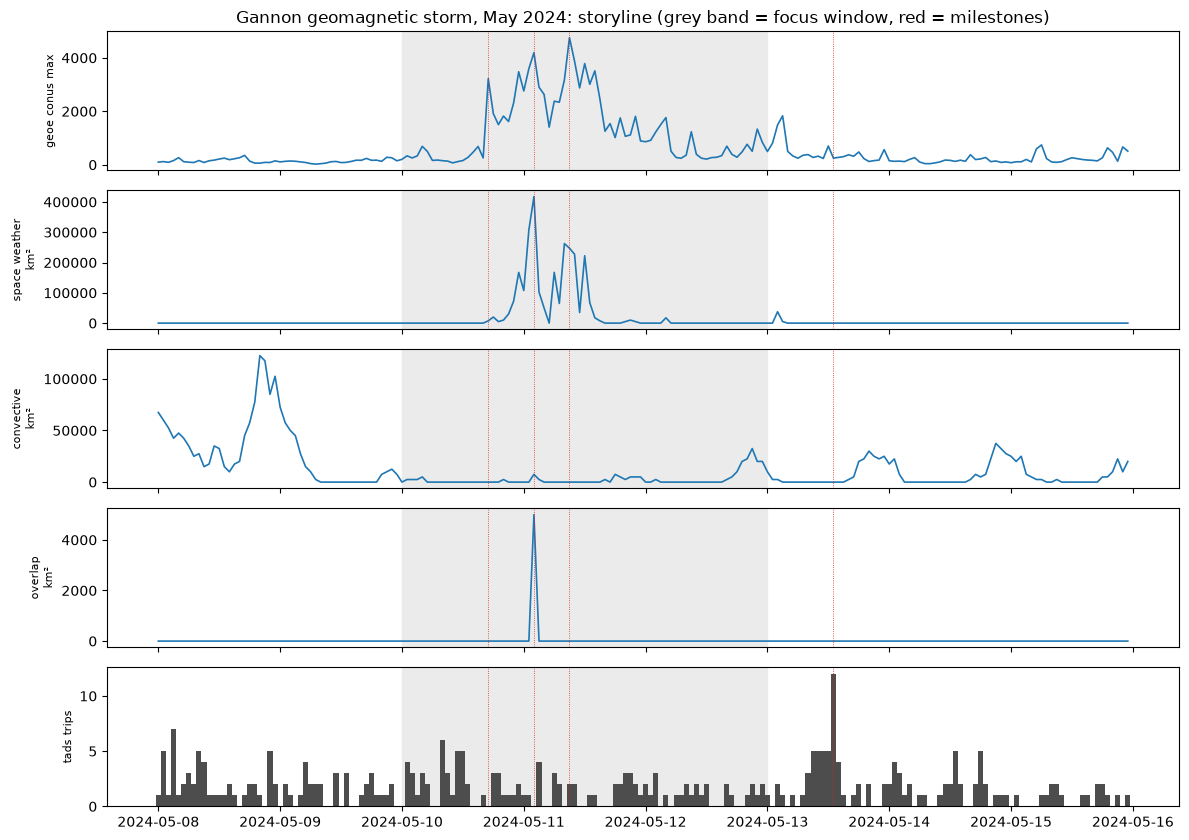

In [19]:
story = pd.DataFrame(index=HOURS)
story.index.name = "hour_utc"
if "series" in HAZARD_DATA.get("space_weather", {}):
    story["geoe_conus_max"] = HAZARD_DATA["space_weather"]["series"].reindex(HOURS)
for key, gdf in LAYERS.items():
    if key.startswith("hazard_") or key == "overlap":
        story[f"{key}_area_km2"] = gdf.groupby("start_time")["area_km2"].sum().reindex(HOURS).fillna(0) if len(gdf) else 0.0
if len(TADS_TRIPS):
    story["tads_trips"] = TADS_TRIPS.groupby(TADS_TRIPS["trip_time"].dt.floor("h")).size().reindex(HOURS).fillna(0).astype(int)
if len(EAGLE_HOURLY):
    story["eagle_customers_out"] = EAGLE_HOURLY.groupby("hour")["customers_out"].sum().reindex(HOURS).fillna(0)
story["outcome_label"] = "unclassified"

milestones = {}
if "hazard_space_weather_area_km2" in story and story["hazard_space_weather_area_km2"].gt(0).any():
    milestones["space-weather hazard first above threshold"] = story.index[story["hazard_space_weather_area_km2"].gt(0)][0]
if "geoe_conus_max" in story and story["geoe_conus_max"].notna().any():
    milestones["peak CONUS |E|"] = story["geoe_conus_max"].idxmax()
if "overlap_area_km2" in story and story["overlap_area_km2"].gt(0).any():
    milestones["largest hazard overlap"] = story["overlap_area_km2"].idxmax()
if "tads_trips" in story and story["tads_trips"].gt(0).any():
    milestones["most TADS trips in one hour"] = story["tads_trips"].idxmax()
for k, v in milestones.items():
    print(f"{k:45s} {v:%Y-%m-%d %H:%M} UTC")

panels = [c for c in ["geoe_conus_max", "hazard_space_weather_area_km2", "hazard_convective_area_km2",
                      "hazard_terrestrial_weather_area_km2", "hazard_wildfire_area_km2", "overlap_area_km2",
                      "tads_trips", "eagle_customers_out"] if c in story]
STORY_FIG, axes = plt.subplots(len(panels), 1, figsize=(12, 1.7 * len(panels)), sharex=True)
for ax, col in zip(np.atleast_1d(axes), panels):
    (ax.bar(story.index, story[col], width=1 / 24, color="0.3") if col == "tads_trips" else ax.plot(story.index, story[col], lw=1.2))
    ax.set_ylabel(col.replace("_area_km2", "\nkm²").replace("hazard_", "").replace("_", " "), fontsize=8)
    ax.axvspan(FOCUS_START, FOCUS_END, color="0.92", zorder=0)
    for t in milestones.values():
        ax.axvline(t, color="tab:red", lw=0.6, ls=":")
np.atleast_1d(axes)[0].set_title(f"{EVENT['title']}: storyline (grey band = focus window, red = milestones)")
plt.tight_layout()
plt.show()

## 12. Preview and save locally

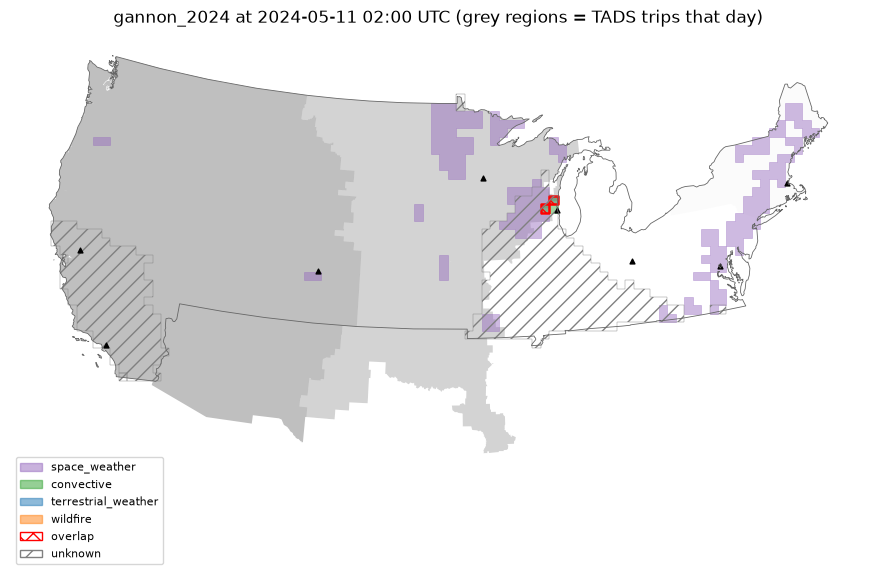

In [20]:
def preview(hour):
    fig, ax = plt.subplots(figsize=(12, 7))
    gpd.GeoSeries([AOI_SIMPLE], crs=ANALYSIS_CRS).boundary.plot(ax=ax, color="0.4", lw=0.6)
    tads = LAYERS.get("grid_tads_regions")
    if tads is not None and len(tads):
        day = tads[(tads["start_time"] >= hour.floor("D")) & (tads["start_time"] < hour.floor("D") + pd.Timedelta("1D"))]
        if len(day):
            day.dissolve("RegionCode", aggfunc={"value": "sum"}).plot(ax=ax, column="value", cmap="Greys", alpha=0.25)
    colors = {"space_weather": "tab:purple", "convective": "tab:green", "terrestrial_weather": "tab:blue", "wildfire": "tab:orange"}
    for fam, col in colors.items():
        g = LAYERS.get(f"hazard_{fam}")
        if g is not None and len(g):
            g[g["start_time"] == hour].plot(ax=ax, color=col, alpha=0.45, edgecolor=col, lw=0.5)
    ov = LAYERS["overlap"]
    if len(ov):
        ov[ov["start_time"] == hour].plot(ax=ax, facecolor="none", edgecolor="red", lw=1.8, hatch="xx")
    unk = LAYERS["unknown_coverage"]
    if len(unk):
        cur = unk[(unk["start_time"] <= hour) & (unk["end_time"] > hour)]
        cur.plot(ax=ax, facecolor="none", edgecolor="0.5", hatch="//", lw=0.3)
    pts = LAYERS["grid_thd_sites"].drop_duplicates("city") if "city" in LAYERS["grid_thd_sites"] else LAYERS["grid_thd_sites"]
    pts.plot(ax=ax, color="black", markersize=12, marker="^")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in colors.values()] + [
        plt.Rectangle((0, 0), 1, 1, fill=False, ec="red", hatch="xx"), plt.Rectangle((0, 0), 1, 1, fill=False, ec="0.5", hatch="//")]
    ax.legend(handles, [*colors, "overlap", "unknown"], loc="lower left", fontsize=8)
    ax.set_title(f"{EVENT_ID} at {hour:%Y-%m-%d %H:%M} UTC (grey regions = TADS trips that day)")
    ax.set_axis_off()
    return fig


if "overlap_area_km2" in story and story["overlap_area_km2"].gt(0).any():
    PREVIEW_HOUR = story["overlap_area_km2"].idxmax()
elif "hazard_space_weather_area_km2" in story and story["hazard_space_weather_area_km2"].gt(0).any():
    PREVIEW_HOUR = story["hazard_space_weather_area_km2"].idxmax()
else:
    PREVIEW_HOUR = FOCUS_START
PREVIEW_FIG = preview(PREVIEW_HOUR)
plt.show()

In [21]:
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
gpkg = OUTPUTS_DIR / f"{EVENT_ID}_multihazard_layers.gpkg"
gpkg.unlink(missing_ok=True)
for key, gdf in LAYERS.items():
    if len(gdf):
        gdf.to_file(gpkg, layer=key, driver="GPKG")

registry_df = pd.DataFrame(REGISTRY.values()).sort_values(["storyline_stage", "layer_key"]).reset_index(drop=True)
registry_df.to_csv(OUTPUTS_DIR / f"{EVENT_ID}_data_registry.csv", index=False)
story.to_csv(OUTPUTS_DIR / f"{EVENT_ID}_storyline_hourly.csv")
PREVIEW_FIG.savefig(OUTPUTS_DIR / f"{EVENT_ID}_preview_map.png", dpi=130, bbox_inches="tight")
STORY_FIG.savefig(OUTPUTS_DIR / f"{EVENT_ID}_storyline.png", dpi=130, bbox_inches="tight")

print("Saved:")
for p in [gpkg, OUTPUTS_DIR / f"{EVENT_ID}_data_registry.csv", OUTPUTS_DIR / f"{EVENT_ID}_storyline_hourly.csv",
          OUTPUTS_DIR / f"{EVENT_ID}_storyline.png", OUTPUTS_DIR / f"{EVENT_ID}_preview_map.png"]:
    print("  ", p.relative_to(PROJECT_DIR))
print()
print(pd.Series({k: len(v) for k, v in LAYERS.items()}, name="features").to_string())
display(registry_df[["layer_key", "storyline_stage", "status", "n_features", "geo_precision", "notes"]])

Saved:
   notebooks/outputs/gannon_2024_multihazard_layers.gpkg
   notebooks/outputs/gannon_2024_data_registry.csv
   notebooks/outputs/gannon_2024_storyline_hourly.csv
   notebooks/outputs/gannon_2024_storyline.png
   notebooks/outputs/gannon_2024_preview_map.png

hazard_space_weather     199
hazard_convective        374
overlap                    2
unknown_coverage           5
grid_tads_regions        206
grid_thd_sites             8
context_psps_circuits    413


,layer_key,storyline_stage,status,n_features,geo_precision,notes
0,overlap,1+2_overlap,loaded,2.0,grid_50km,"families considered: space_weather, convective..."
1,hazard_space_weather,1_space_weather_forcing,loaded,199.0,grid_50km,"8/8 daily files; |E| = hypot(Ex, Ey), hourly m..."
2,hazard_convective,2_terrestrial_conditions,loaded,374.0,grid_50km,"nx3hail: 47,711 records; nx3tvs: 4,094 records..."
3,hazard_terrestrial_weather,2_terrestrial_conditions,missing_input,NaN,,FileNotFoundError: no weather_CONUS_YYYYMMDD.n...
4,hazard_wildfire,2_terrestrial_conditions,missing_input,NaN,,FileNotFoundError: no fires_analysis_grid_YYYY...
5,grid_component_outages,3_grid_stress,not_yet_available,NaN,,TADS rows are anonymized (AliasID); needs the ...
6,grid_eagle_i,3_grid_stress,missing_input,NaN,county,Eagle-I file not found: /Users/nza/Downloads/m...
7,grid_gic_measurements,3_grid_stress,not_yet_available,NaN,,Exists on a collaborator machine (NERC_GIC_Gan...
8,grid_pjm_operations,3_grid_stress,not_yet_available,NaN,,PJM notebooks are exploratory; no event extrac...
9,grid_tads_regions,3_grid_stress,loaded,206.0,nerc_region,293 trips in window; 0 trips with unmapped reg...


## 13. Publish to ArcGIS Online

This follows the pattern tested in `Untitled.ipynb`:
1. `to_featurelayer` uploads each layer in EPSG:5070, one at a time. Parallel uploads caused GDAL errors in `create_hazard_polygons.ipynb`.
2. `timeInfo` is set on time-enabled layers, using `start_time` / `end_time` with a 1-hour interval.
3. `gis.map(...)`, `content.add` with a renderer, then `save` builds the web map.

New compared with the tested notebook (written carefully, but not yet run against ArcGIS Online):
- the renderer is also written into each layer's definition;
- the time slider opens on the focus window;
- `WEB_MAP_ITEM_ID` overwrites an existing map in place;
- tag-based cleanup of earlier runs.

Layers stack in storyline order. Context sits at the bottom, then grid stress, then hazards, with overlap and unknowns on top.

In [22]:
def fill(rgba, outline=None, width=0.6, style="esriSFSSolid"):
    return {"type": "esriSFS", "style": style, "color": rgba,
            "outline": {"type": "esriSLS", "style": "esriSLSSolid", "color": outline or rgba[:3] + [255], "width": width}}


def simple(symbol):
    return {"type": "simple", "symbol": symbol}


def class_breaks(field, breaks, colors, labels, outline=None):
    lo = breaks[0]
    infos = [{"classMaxValue": hi, "label": lab, "symbol": fill(c, outline)} for hi, c, lab in zip(breaks[1:], colors, labels)]
    return {"type": "classBreaks", "field": field, "minValue": lo, "classBreakInfos": infos}


def unique_values(field, mapping, default):
    return {"type": "uniqueValue", "field1": field, "defaultSymbol": default, "defaultLabel": "other",
            "uniqueValueInfos": [{"value": str(v), "label": lab, "symbol": sym} for v, (lab, sym) in mapping.items()]}


thr = HAZARD_RULES["space_weather"]["config"]["thresholds"]["E_hmax"]["value"]
RENDERERS = {
    "context_psps_circuits": simple(fill([255, 255, 255, 0], [120, 120, 120, 200], 0.5)),
    "grid_tads_regions": class_breaks("value", [0, 1, 3, 9, 1e9], [[255, 237, 160, 70], [254, 178, 76, 90], [240, 59, 32, 100], [128, 0, 38, 110]],
                                      ["1 trip", "2–3 trips", "4–9 trips", "10+ trips"], [90, 90, 90, 160]),
    "grid_eagle_i": class_breaks("value", [0, 5_000, 50_000, 1e12], [[253, 208, 162, 140], [241, 105, 19, 150], [127, 39, 4, 160]],
                                 ["< 5k customers", "5k–50k", "50k+"], [90, 90, 90, 200]),
    "hazard_wildfire": simple(fill([255, 75, 50, 120], [180, 30, 20, 255], 1)),
    "hazard_terrestrial_weather": simple(fill([50, 120, 255, 100], [20, 70, 180, 255], 1)),
    "hazard_convective": simple(fill([40, 170, 90, 110], [10, 110, 50, 255], 1)),
    "hazard_space_weather": class_breaks("value", [0, thr * 2, thr * 4, 1e12],
                                         [[188, 128, 255, 90], [128, 60, 220, 120], [74, 20, 140, 150]],
                                         [f"{thr:g}–{thr * 2:g}", f"{thr * 2:g}–{thr * 4:g}", f"> {thr * 4:g}"], [80, 30, 140, 255]),
    "overlap": unique_values("n_hazards", {2: ("2 hazards", fill([255, 140, 0, 150], [200, 60, 0, 255], 1.5)),
                                           3: ("3 hazards", fill([230, 30, 30, 170], [140, 0, 0, 255], 1.5)),
                                           4: ("4 hazards", fill([120, 0, 0, 190], [60, 0, 0, 255], 1.5))},
                             fill([255, 140, 0, 150])),
    "unknown_coverage": simple(fill([110, 110, 110, 140], [110, 110, 110, 200], 0.4, style="esriSFSBackwardDiagonal")),
    "grid_thd_sites": {"type": "simple", "symbol": {"type": "esriSMS", "style": "esriSMSTriangle", "color": [20, 20, 20, 230], "size": 10,
                                                     "outline": {"color": [255, 255, 255, 255], "width": 1}}},
}
MAP_ORDER = ["context_psps_circuits", "grid_tads_regions", "grid_eagle_i", "hazard_wildfire", "hazard_terrestrial_weather",
             "hazard_convective", "hazard_space_weather", "overlap", "unknown_coverage", "grid_thd_sites"]
STATIC_LAYERS = {"context_psps_circuits"} | (set() if THD_TIME_ENABLED else {"grid_thd_sites"})
LAYER_TITLES = {
    "context_psps_circuits": "Context: PSPS circuit footprints",
    "grid_tads_regions": "3 Grid stress: TADS circuit trips by NERC region",
    "grid_eagle_i": "3 Grid stress: Eagle-I county outages",
    "grid_thd_sites": "3 Grid stress: Whisker THD sensor cities",
    "hazard_space_weather": "1 Space weather: geoelectric field",
    "hazard_convective": "2 Terrestrial: severe convection (radar)",
    "hazard_terrestrial_weather": "2 Terrestrial: high wind",
    "hazard_wildfire": "2 Terrestrial: active fire",
    "overlap": "Overlapping hazards",
    "unknown_coverage": "Unknown / low-confidence coverage",
}
APP_TAG, LAYER_TAG, MAP_TAG, EVENT_TAG = "multihazard", "multihazard-layer", "multihazard-webmap", f"event-{EVENT_ID}"


def prepare_for_publish(gdf):
    out = gdf.to_crs(ANALYSIS_CRS)
    out = out[out.geometry.notna() & ~out.geometry.is_empty].copy()
    bad = ~out.geometry.is_valid
    if bad.any():
        out.loc[bad, "geometry"] = out.loc[bad, "geometry"].buffer(0)
    for c in out.columns:
        if c != "geometry" and out[c].dtype == object:
            out[c] = out[c].astype(str)
    return out


def publish_layer(gis, key, gdf):
    tags = [APP_TAG, LAYER_TAG, EVENT_TAG, f"layer-{key}"]
    sedf = pd.DataFrame.spatial.from_geodataframe(prepare_for_publish(gdf))
    item = sedf.spatial.to_featurelayer(
        title=f"{EVENT_ID}: {LAYER_TITLES[key]}",
        gis=gis,
        folder=ARCGIS_FOLDER,
        service_name=f"mh_{EVENT_ID}_{key}_{uuid4().hex[:6]}",
        tags=",".join(tags),
    )
    try:
        item.update(item_properties={"tags": tags, "snippet": f"{LAYER_TITLES[key]} ({EVENT['title']})"})
    except Exception as exc:
        print(f"  could not update tags for {key}: {exc}")
    layer = item.layers[0]
    if key not in STATIC_LAYERS:
        layer.manager.update_definition({"timeInfo": {
            "startTimeField": "start_time", "endTimeField": "end_time",
            "timeInterval": 1, "timeIntervalUnits": "esriTimeUnitsHours",
        }})
    try:
        layer.manager.update_definition({"drawingInfo": {"renderer": RENDERERS[key]}})
    except Exception as exc:
        print(f"  renderer not stored on {key} (the map still applies it): {exc}")
    layer.manager.refresh()
    return item

In [23]:
PUBLISHED = {}
if not PUBLISH_TO_ARCGIS:
    print("PUBLISH_TO_ARCGIS is False. Set it to True in section 1 and rerun from here to publish.")
else:
    import importlib.util
    if importlib.util.find_spec("osgeo") is None and importlib.util.find_spec("arcpy") is None:
        raise RuntimeError(
            "This kernel has neither GDAL (osgeo) nor arcpy, so arcgis would upload through shapefiles "
            "(hourly times lost, field names cut to 10 characters). Switch the kernel to the gdal_test env."
        )
    from arcgis.gis import GIS
    from arcgis.features import GeoAccessor  # noqa: F401  (registers DataFrame.spatial)

    gis = GIS(profile=GIS_PROFILE)
    print("Signed in as", gis.users.me.username)
    gis.content.folders.create(ARCGIS_FOLDER, exist_ok=True)
    for key in MAP_ORDER:
        gdf = LAYERS.get(key)
        if gdf is None or not len(gdf):
            continue
        print(f"Publishing {key} ({len(gdf):,} features) …")
        try:
            PUBLISHED[key] = publish_layer(gis, key, gdf)
            print(f"  → {PUBLISHED[key].id}")
        except Exception as exc:
            print(f"  FAILED {key}: {type(exc).__name__}: {exc}")

Profile your_online_profile does not have a password on file through keyring. If you are expecting this behavior (PKI or IWA authentication, entering password through run-time prompt, etc.), please ignore this message. If you would like to store your password in the your_online_profile profile, run GIS(profile = 'your_online_profile', password = ...). See the API doc for more details. (https://developers.arcgis.com/python/api-reference/arcgis.gis.toc.html#gis)


AttributeError: 'NoneType' object has no attribute 'username'

In [ ]:
def registry_html(df):
    rows = "".join(
        f"<tr><td>{r.layer_key}</td><td>{r.storyline_stage}</td><td>{r.status}</td><td>{r.notes}</td></tr>"
        for r in df.itertuples()
    )
    return ("<p>Time-enabled multi-hazard layers for the storyline: space-weather forcing → terrestrial conditions → "
            "grid stress → outcome. Hatched grey = places where a hazard cannot be assessed.</p>"
            "<p><b>Data registry</b> (missing and not-yet-available signals are listed on purpose):</p>"
            f"<table><tr><th>layer</th><th>stage</th><th>status</th><th>notes</th></tr>{rows}</table>")


MAP_ITEM = None
if PUBLISH_TO_ARCGIS and PUBLISHED:
    wm = gis.map("USA")
    for key in MAP_ORDER:
        if key in PUBLISHED:
            wm.content.add(PUBLISHED[key], options={"drawingInfo": {"renderer": RENDERERS[key]}})
    MAP_ITEM = wm.save(item_properties={
        "title": f"{EVENT['title']}: multi-hazard storyline",
        "tags": [APP_TAG, MAP_TAG, EVENT_TAG],
        "snippet": f"Time-enabled hazard, overlap, grid-stress and unknown-coverage layers for {EVENT_ID}",
        "description": registry_html(registry_df),
    }, folder=ARCGIS_FOLDER)
    print("Web map:", MAP_ITEM.id, MAP_ITEM.homepage)

    # Open the time slider on the focus window, stepping hourly (not yet tested)
    try:
        data = MAP_ITEM.get_data()
        ms = lambda t: int(pd.Timestamp(t).tz_localize("UTC").timestamp() * 1000)
        data.setdefault("widgets", {})["timeSlider"] = {"properties": {
            "startTime": ms(FOCUS_START), "endTime": ms(FOCUS_START + STEP), "thumbCount": 2,
            "thumbMovingRate": 1500, "timeStopInterval": {"interval": 1, "units": "esriTimeUnitsHours"},
        }}
        MAP_ITEM.update(item_properties={"text": json.dumps(data)})
    except Exception as exc:
        print("  time slider defaults not set:", exc)

    # Optional: copy into an existing web map so Experience Builder keeps its link (not yet tested)
    if WEB_MAP_ITEM_ID.strip():
        target = gis.content.get(WEB_MAP_ITEM_ID.strip())
        if target is None:
            print("WEB_MAP_ITEM_ID not found; keeping the new map", MAP_ITEM.id)
        else:
            target.update(item_properties={"text": json.dumps(MAP_ITEM.get_data()), "description": registry_html(registry_df)})
            MAP_ITEM.delete()
            MAP_ITEM = target
            print("Updated existing web map", MAP_ITEM.id)

In [ ]:
if PUBLISH_TO_ARCGIS and PUBLISHED:
    me = gis.users.me.username
    new_ids = {it.id for it in PUBLISHED.values()}
    old = [it for it in gis.content.search(f'owner:"{me}" tags:"{LAYER_TAG}" tags:"{EVENT_TAG}"', item_type="Feature Service", max_items=500)
           if it.id not in new_ids]
    print(f"{len(old)} layer items from earlier runs of {EVENT_ID}:")
    for it in old:
        print("  ", it.id, it.title, pd.Timestamp(it.modified, unit="ms"))
    if DELETE_PREVIOUS_LAYERS:
        for it in old:
            try:
                it.delete(permanent=True)
            except TypeError:
                it.delete()
        print("Deleted.")
    elif old:
        print("Kept (set DELETE_PREVIOUS_LAYERS = True to remove them).")

    print("\nPublished layers:")
    for key, it in PUBLISHED.items():
        print(f"  {key:28s} {it.id}  {it.title}")
    if MAP_ITEM is not None:
        print("\nWeb map for Experience Builder:", MAP_ITEM.id)

## 14. Using it in Experience Builder

1. **Map widget** → choose the web map printed above. If you rerun with `WEB_MAP_ITEM_ID` set to it, the app keeps working with the new layers.
2. **Timeline widget** → connect it to the map. It picks up every time-enabled layer and steps hourly. Static layers (PSPS circuits, and THD cities when no THD series is loaded) show all the time.
3. **Layer List + Legend** → layer titles start with their storyline stage (1 space weather, 2 terrestrial, 3 grid stress), so the list reads in causal order.
4. **Filters / table**: the shared fields (`family`, `hazard_combo`, `n_hazards`, `data_status`, `geo_precision`) work the same on every layer. For example, filter `data_status = 'unknown'`, or `n_hazards >= 3`.
5. **Storyline text**: use `outputs/<event>_storyline_hourly.csv` and the milestones printed in section 11 for the narrative. Fill in `outcome_label` there.

### Adding a new contextual layer later
Make a GeoDataFrame with `start_time` / `end_time` in UTC, then pass it through `conform(...)` with `family`, `storyline_stage`, `data_status` and `geo_precision`. Add it to `LAYERS`, `MAP_ORDER`, `LAYER_TITLES` and `RENDERERS`, and `register(...)` it. Nothing else needs to change.